# Part 3 - Doubly stochastic system

We choose the AR(1)-AR(2) model

### Imorting necessary packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Defining parameters

In [2]:
phi1 = 0.75
phi2 = 0.15
mu = 0.8
sigma_zeta = 0.1     # latent-state innovation
sigma_eps = 4        # observation noise 

# Defining delta for the AR(2) process
delta = mu * (1 - phi1 - phi2)

### Checking for stationarity

In [3]:
# Finding the roots of the characteristic polynomial of the AR(2) process to check stationarity
# Roots of 1 - phi1*z - phi2*z**2 = 0 (1-0.8z-0.15z^2=0)
roots = np.roots([-phi2, -phi1, 1])

print("Roots:", roots)
print("Absolute values of roots:", np.abs(roots))
print("Stationary:", np.all(np.abs(roots) > 1))

Roots: [-6.09397644  1.09397644]
Absolute values of roots: [6.09397644 1.09397644]
Stationary: True


## Simulation

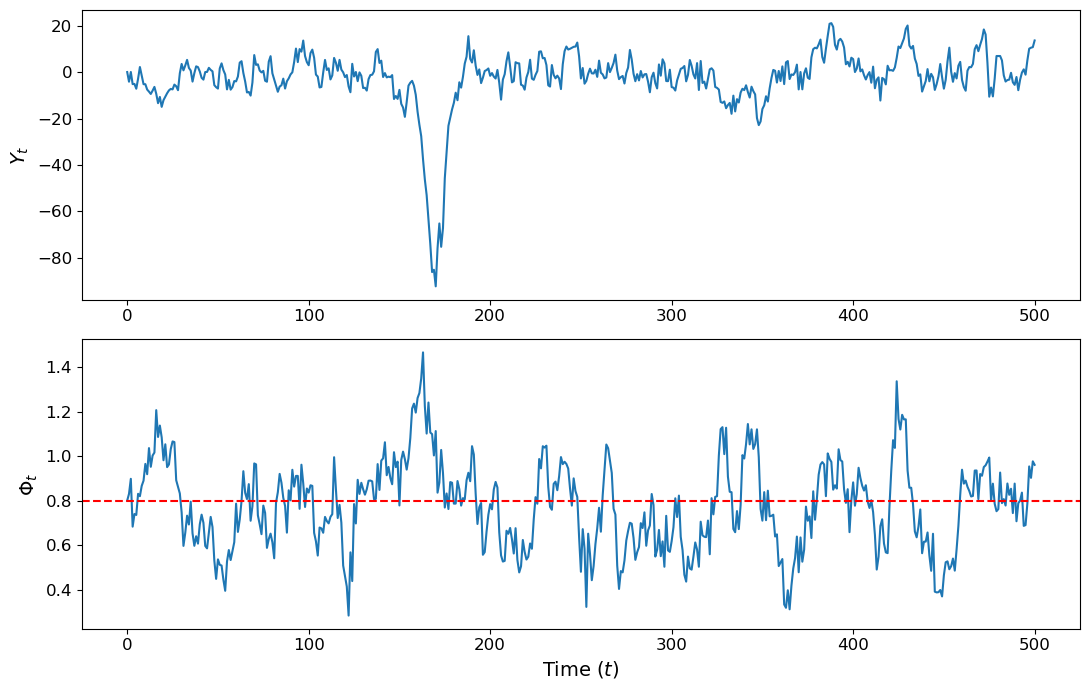

Observed Y range: [-92.21, 21.05]
Latent Phi range: [0.283, 1.466]
Fraction of times Phi > 1: 0.12


In [4]:
# Defining the simulation length
N = 500

# Setting a seed for reproducibility
SEED = 42

# Defining the simulation function
def simulate_ar1_ar2(N, phi1, phi2, mu, sigma_zeta, sigma_eps, seed=42):    # takes the parameters of our doubly stochastic model as input
    """Simulate Y_t = Phi_t Y_(t-1) + eps_t, with an AR(2) Phi_t."""

    # Intilizing the simulation
    rng = np.random.default_rng(seed)   # creates a random number generator to use in the simulation of the standard deviations
    Phi = np.zeros(N + 1)   # array to store the latent process
    Y = np.zeros(N + 1)     # array to store the observed process

    # Defining initial conditions
    Phi[0] = mu
    phi_minus_one = mu
    Y[0] = 0.0

    for t in range(1, N + 1):   # loop over t=1,...,N
        phi_lag2 = Phi[t-2] if t >= 2 else phi_minus_one
        # Simulating the hidden coefficient
        Phi[t] = (mu
                  + phi1 * (Phi[t-1] - mu)
                  + phi2 * (phi_lag2 - mu)
                  + rng.normal(0.0, sigma_zeta))
        # Simulating the observed process
        Y[t] = Phi[t] * Y[t-1] + rng.normal(0.0, sigma_eps)

    # Returning the simulated time series
    return {'Y': Y, 'Phi': Phi}

# Running the simulation
sim = simulate_ar1_ar2(N, phi1, phi2, mu, sigma_zeta, sigma_eps, SEED)
Y, Phi_true = sim['Y'], sim['Phi']
t = np.arange(N + 1)

# Checking the simulation results
assert len(Y) == N + 1 and len(Phi_true) == N + 1
assert np.all(np.isfinite(Y)) and np.all(np.isfinite(Phi_true))


# Plotting the simulation
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(t, Y)
axes[0].set_ylabel('$Y_t$', size=14)
axes[0].tick_params(axis='both', labelsize=12)
axes[1].plot(t, Phi_true)
axes[1].axhline(mu, ls='--', color='red')   # the mean of the latent process
axes[1].set_ylabel('$\\Phi_t$', size=14)
axes[1].set_xlabel('Time ($t$)', size=14)
axes[1].tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.show()

# Printing some statistics about the simulation
print(f'Observed Y range: [{Y.min():.2f}, {Y.max():.2f}]')
print(f'Latent Phi range: [{Phi_true.min():.3f}, {Phi_true.max():.3f}]')
print('Fraction of times Phi > 1:', np.mean(Phi_true[1:] > 1).round(3))

## Using the Kalman filter to estimate the state based on the simulated measurements.

In [5]:
# State transition matrix
A = np.array([
    [phi1, phi2, 1],
    [1,    0,    0],
    [0,    0,    1]
])

# Process and observation noise variances
Q = np.diag([sigma_zeta**2, 0, 0])
R = sigma_eps**2

# Initializing arrays for storing filtered states and covariance matrices
X_filtered = np.zeros((N + 1, 3))       # filtered states
P_filtered = np.zeros((N + 1, 3, 3))    # filtered covariance matrices

# Initial state (same known initial conditions as simulation)
X_filtered[0] = [mu, mu, delta]
P_filtered[0] = np.zeros((3, 3))

I = np.eye(3)   # Identity matrix

# Kalman filter
for k in range(1, N + 1):

    # Predicting the state and its covariance
    X_pred = A @ X_filtered[k-1]
    P_pred = A @ P_filtered[k-1] @ A.T + Q

    # Observation matrix depends on previous observation
    C = np.array([[Y[k-1], 0, 0]])

    # Calculating prediction error and Kalman gain
    innovation = Y[k] - (C @ X_pred).item()
    S = (C @ P_pred @ C.T).item() + R
    K = (P_pred @ C.T / S).flatten()

    # Updating the state estimate
    X_filtered[k] = X_pred + K * innovation
    # Updating the covariance matrix
    P_filtered[k] = (I - np.outer(K, C.flatten())) @ P_pred

# Extracting the estimate of the hidden coefficient Phi_t
Phi_est = X_filtered[:, 0]

# Estimated standard deviation
Phi_std = np.sqrt(P_filtered[:, 0, 0])


## Plotting the true and Kalman estimated coefficients

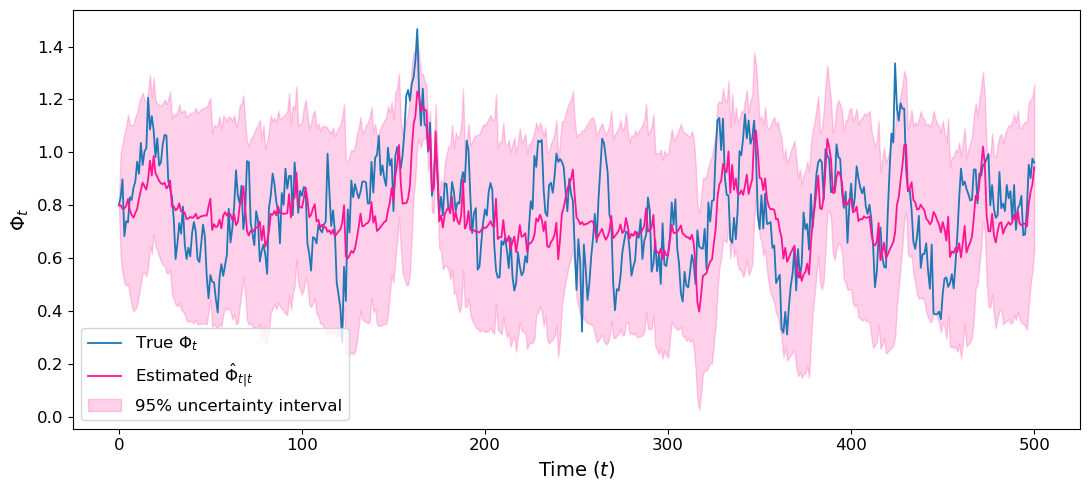

In [6]:
# Constructing 95% uncertainty interval for the filtered estimate
lower = Phi_est - 1.96 * Phi_std
upper = Phi_est + 1.96 * Phi_std

# Setting up the plot
fig, ax = plt.subplots(figsize=(11, 5))

# True hidden coefficient
ax.plot(t, Phi_true,
        color='tab:blue',
        linewidth=1.3,
        label=r'True $\Phi_t$')

# Kalman filter estimate
ax.plot(t, Phi_est,
        color='deeppink',
        linewidth=1.3,
        label=r'Estimated $\hat{\Phi}_{t|t}$')

# 95% uncertainty interval
ax.fill_between(t, lower, upper,
                color='deeppink',
                alpha=0.2,
                label='95% uncertainty interval')

ax.set_xlabel('Time ($t$)', fontsize=14)
ax.set_ylabel(r'$\Phi_t$', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
ax.legend(fontsize=12, loc='lower left')

plt.tight_layout()
plt.show()

In [7]:
rmse = np.sqrt(np.mean((Phi_true[1:] - Phi_est[1:])**2))

coverage = np.mean(
    (Phi_true[1:] >= lower[1:]) &
    (Phi_true[1:] <= upper[1:])
)

print(f"RMSE: {rmse:.4f}")
print(f"95% interval coverage: {coverage:.1%}")

RMSE: 0.1627
95% interval coverage: 97.4%
